Modelling and Model Selection: compares four classifiers, tunes their hyperparameters using F1 score, chooses decision thresholds using development-only out-of-fold predictions, and compares the tuned options on a separate selection-validation partition. The final 20% test partition remains reserved for the evaluation notebook.

In [1]:
# Import the required libraries, and open and read the dataset.
from pathlib import Path
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler

# Keeps file paths relative to the project.
DATA_DIR = Path('../data')
DATA_PATH = DATA_DIR / 'bank_personalized.csv'
if not DATA_PATH.is_file(): raise FileNotFoundError(f'Dataset not found: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully:', df.shape)

Dataset loaded successfully: (36168, 17)


In [2]:
# Encode the target, exclude post-call duration, and reserve the untouched 20% test set.
RANDOM_STATE = 202300404
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})
assert y.notna().all(), 'Unexpected target labels found.'

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=RANDOM_STATE, 
    stratify=y
)

# Split the training partition again: development for tuning and selection-validation for comparisons.
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train, y_train, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train,
)
print('Development:', X_dev.shape, '| Selection-validation:', X_val.shape)
print('Reserved test:', X_test.shape)
print('Development target proportions (%):')
print(y_dev.value_counts(normalize=True).mul(100).round(2))

Development: (23147, 15) | Selection-validation: (5787, 15)
Reserved test: (7234, 15)
Development target proportions (%):
y
0    88.3
1    11.7
Name: proportion, dtype: float64


## Model choices:

- **Logistic Regression:** An interpretable linear baseline; useful for assessing how much predictive signal is approximately linear after one-hot encoding.
- **Random Forest:** An ensemble of decision trees that can capture nonlinear relations and interactions without assuming a linear boundary.
- **Histogram Gradient Boosting:** Sequentially improves trees using gradient boosting; a strong scikit-learn tabular-data baseline.
- **LightGBM:** An efficient gradient-boosted tree implementation designed for tabular datasets; its distinct growth/regularization choices may improve ranking or classification.

**Evaluation:** All models receive the same five shuffled stratified folds on the development partition. F1 is the primary model-selection metric because both missed subscribers (false negatives) and unnecessary positive predictions (false positives) matter. Accuracy alone is less informative with ~12% positive cases. Precision, recall, ROC AUC, and average precision provide supporting views of performance. Average precision evaluates ranking across thresholds and is especially helpful with an imbalanced target.

**Selection without test leakage:** First compare baseline configurations, then tune all four models by randomized search, scoring F1. Next, derive probability thresholds from development out-of-fold probabilities. These are threshold candidates rather than independently verified scores. Compare each tuned model and its chosen threshold on the held-out selection-validation partition to choose a final configuration. Retrain the selected pipeline on the complete training partition, save the chosen threshold with the pipeline, and leave the final test partition untouched for the subsequent evaluation notebook. Because the selection-validation partition is used to choose a winner, its winning score is still a model-selection estimate, not the final unbiased test result.

In [3]:
# Define feature engineering and a fold-safe preprocessing pipeline. all transformations are fitted inside model cross-validation.

# Derive previous-contact and log-count features without modifying the original df.
def engineer_features(data):
    data = data.copy()

    assert data["campaign"].ge(0).all()
    assert data["previous"].ge(0).all()
    assert (data["pdays"].eq(-1) | data["pdays"].ge(0)).all()

    days_since_previous_contact = data["pdays"].replace(-1, 0)
    data["previously_contacted"] = data["pdays"].ne(-1).astype(int)
    data["campaign_log1p"] = np.log1p(data["campaign"])
    data["previous_log1p"] = np.log1p(data["previous"])
    data["days_since_previous_contact_log1p"] = np.log1p(days_since_previous_contact)

    assert (
        data["previously_contacted"] == data["previous"].gt(0).astype(int)
    ).all()

    return data.drop(columns=["pdays", "campaign", "previous"])


categorical_features = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "poutcome",
]
numerical_features = [
    "age", "balance", "day", "campaign_log1p", "previous_log1p",
    "days_since_previous_contact_log1p",
]
binary_features = ["previously_contacted"]


# Build separate categorical and numerical preprocessing steps for every pipeline fit.
def make_feature_pipeline():
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical", categorical_pipeline, categorical_features),
            ("numerical", numerical_pipeline, numerical_features),
            ("binary", "passthrough", binary_features),
        ],
        remainder="drop",
    )

    return Pipeline([
        ("feature_engineering", FunctionTransformer(engineer_features, validate=False)),
        ("preprocessing", preprocessor),
    ])


# Attach the classifier after preprocessing so the validation fold never fits transformations.
def make_model_pipeline(estimator):
    return Pipeline([
        ("features", make_feature_pipeline()),
        ("model", estimator),
    ])


engineered_columns = set(engineer_features(X_train.head()).columns)
expected_columns = set(categorical_features + numerical_features + binary_features)
assert engineered_columns == expected_columns
print("Pipeline definition validated for", len(expected_columns), "engineered input features.")

Pipeline definition validated for 16 engineered input features.


In [4]:
# Define four baseline models and the same reproducible stratified folds for all of them.
# All reported values in this section are validation-fold estimates from the training partition, not held-out test results.

# cv = 5-fold, shuffled, stratified, reproducible cross-validation.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# define the metrics we want cross_validate() to calculate.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

# Define the models to be used.
models = {
    "Logistic regression": LogisticRegression(
        max_iter=2000,              # max number of iterations is 2000
        solver="liblinear",         # internal algorithm used to optimize the model (this one is good for binary classification)
        class_weight="balanced",    # prevent model from favoring the majority class
        random_state=RANDOM_STATE,
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200,                   # use 200 decision trees
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1,                           # each random forest fit uses one CPU worker 
    ),
    "Gradient boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "LightGBM": LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=30,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=-1,
    ),
    
}

In [5]:
# Evaluate every baseline model with the same development-only five-fold cross-validation.
cv_rows = [] 
# Empty dictionary to store full results for every individual fold.
fold_results = {}


# This loop runs 5-fold cross-validation for each model using the complete preprocessing pipeline, 
# evaluates it using the specified metrics, and stores the results for all five folds in fold_results under each model's name.
for model_name, estimator in models.items():
    result = cross_validate(
        make_model_pipeline(estimator),
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )
    fold_results[model_name] = result

    row = {"model": model_name}
    
    # This code calculates the mean and standard deviation of each evaluation metric across the five folds for the current model, 
    # then stores the summary as a row in cv_rows.
    for metric in scoring:
        values = result[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    cv_rows.append(row)

cv_summary = pd.DataFrame(cv_rows).set_index("model")
display(cv_summary.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
model,,,,,,,,,,,,
Logistic regression,0.7619,0.0047,0.2735,0.0063,0.6252,0.0126,0.3806,0.0081,0.7633,0.0084,0.4041,0.0166
Random forest,0.8940,0.0012,0.6433,0.0150,0.2105,0.0067,0.3172,0.0091,0.7778,0.0106,0.4240,0.0107
Gradient boosting,0.8236,0.0039,0.3524,0.0064,0.6052,0.0101,0.4454,0.0055,0.7872,0.0085,0.4401,0.0186
LightGBM,0.8937,0.0021,0.6168,0.0264,0.2422,0.0076,0.3477,0.0093,0.7912,0.0099,0.4498,0.0232


## Interpreting the baseline metrics

- **Accuracy:** The proportion of all predictions that are correct. A majority-class prediction can achieve high accuracy even when few subscribers are identified.
- **Precision:** Of the customers predicted to subscribe, the proportion who actually subscribe; low precision means many unnecessary positive predictions.
- **Recall:** Of all actual subscribers, the proportion detected; low recall means many missed potential subscribers.
- **F1:** The harmonic mean of precision and recall at the current decision threshold; the main selection objective here.
- **ROC AUC:** How well predicted scores rank positive cases above negative cases across thresholds; it is not the same as accuracy.
- **Average Precision:** A summary of the precision–recall ranking curve, particularly informative for rare subscribers.
- **Standard deviation:** Describes variation among the five validation-fold scores; it is not a confidence interval or proof of generalization.

In [6]:
for model_name, row in cv_summary.iterrows():
    # Use the reported means, not predictions on the reserved test set.
    display(Markdown(
        f"- **{model_name}:** Accuracy **{row['accuracy_mean']:.4f}**, "
        f"precision **{row['precision_mean']:.4f}**, recall **{row['recall_mean']:.4f}**, "
        f"F1 **{row['f1_mean']:.4f}**, ROC AUC **{row['roc_auc_mean']:.4f}**, "
        f"average precision **{row['average_precision_mean']:.4f}** "
        f"(F1 fold SD **{row['f1_std']:.4f}**). "
        + ('The model favors identifying more subscribers but may produce more false positives.'
           if row['recall_mean'] > row['precision_mean']
           else 'The model is more selective with positive predictions but may miss subscribers.')
    ))

# Identify metric leaders without assuming one model wins every metric.
for metric in ['f1', 'precision', 'recall', 'roc_auc', 'average_precision']:
    winner = cv_summary[f'{metric}_mean'].idxmax()
    print(f'Highest baseline {metric}: {winner} ({cv_summary.loc[winner, f"{metric}_mean"]:.4f})')

- **Logistic regression:** Accuracy **0.7619**, precision **0.2735**, recall **0.6252**, F1 **0.3806**, ROC AUC **0.7633**, average precision **0.4041** (F1 fold SD **0.0081**). The model favors identifying more subscribers but may produce more false positives.

- **Random forest:** Accuracy **0.8940**, precision **0.6433**, recall **0.2105**, F1 **0.3172**, ROC AUC **0.7778**, average precision **0.4240** (F1 fold SD **0.0091**). The model is more selective with positive predictions but may miss subscribers.

- **Gradient boosting:** Accuracy **0.8236**, precision **0.3524**, recall **0.6052**, F1 **0.4454**, ROC AUC **0.7872**, average precision **0.4401** (F1 fold SD **0.0055**). The model favors identifying more subscribers but may produce more false positives.

- **LightGBM:** Accuracy **0.8937**, precision **0.6168**, recall **0.2422**, F1 **0.3477**, ROC AUC **0.7912**, average precision **0.4498** (F1 fold SD **0.0093**). The model is more selective with positive predictions but may miss subscribers.

Highest baseline f1: Gradient boosting (0.4454)
Highest baseline precision: Random forest (0.6433)
Highest baseline recall: Logistic regression (0.6252)
Highest baseline roc_auc: LightGBM (0.7912)
Highest baseline average_precision: LightGBM (0.4498)


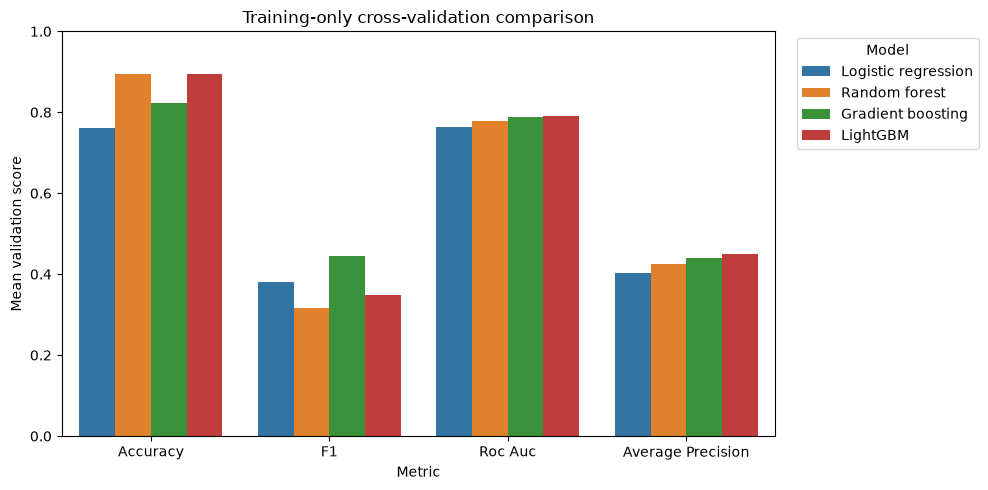

In [7]:
# Plot the development-fold baseline metrics to compare the models visually.
plot_data = (
    cv_summary[["accuracy_mean", "f1_mean", "roc_auc_mean", "average_precision_mean"]]
    .rename(columns=lambda name: name.replace("_mean", "").replace("_", " ").title())
    .reset_index()
    .melt(id_vars="model", var_name="metric", value_name="mean_cv_score")
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_data, x="metric", y="mean_cv_score", hue="model")
ax.set(
    title="Training-only cross-validation comparison",
    xlabel="Metric",
    ylabel="Mean validation score",
    ylim=(0, 1),
)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Hyperparameter tuning

The original baseline settings establish an initial comparison, not optimal models. `RandomizedSearchCV` samples 20 combinations per model and evaluates each using the same five folds of the development set. Keep F1 as the refit criteria while recording the remaining metrics. Each search refits its selected model on development data only. Because the best score is selected from several configurations, the search's reported best cross-validation F1 may be optimistic. The next selection-validation stage is separate from this search.

In [8]:
# Tune all four model families on development folds using F1 as the primary criterion.
# Define model-specific hyperparameter spaces for all four classifiers.
parameter_spaces = {
    "Logistic regression": {
        "model__C": np.logspace(-3, 2, 30),
        "model__l1_ratio": [0.0, 1.0],  # 0 = L2; 1 = L1 (modern sklearn API)
        "model__class_weight": [None, "balanced"],
    },

    "Random forest": {
        "model__n_estimators": [150, 250, 350],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5, 0.8],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
    },

    "Gradient boosting": {
        "model__max_iter": [100, 200, 300, 400],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [10, 20, 30, 50],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },

    "LightGBM": {
        "model__n_estimators": [150, 250, 350, 500],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__num_leaves": [7, 15, 31, 63],
        "model__max_depth": [-1, 5, 10, 15],
        "model__min_child_samples": [10, 20, 30, 50],
        "model__reg_lambda": [0.0, 0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
}

# 2. Store the tuning results and best fitted pipelines.
tuning_results = []
tuned_models = {}
tuning_searches = {}

# 3. Perform hyperparameter tuning for every model.
for model_name, estimator in models.items():

    print(f"\nTuning {model_name}...")

    search = RandomizedSearchCV(
        estimator=make_model_pipeline(clone(estimator)),
        param_distributions=parameter_spaces[model_name],
        n_iter=20,
        scoring=scoring,
        refit="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=False,
        verbose=1,
    )

    search.fit(X_dev, y_dev)

    # Save the fitted search and best model.
    tuning_searches[model_name] = search
    tuned_models[model_name] = search.best_estimator_

    # Retrieve the best configuration's CV metrics.
    best_index = search.best_index_
    cv_results = search.cv_results_

    row = {
        "model": model_name,
        "baseline_f1": cv_summary.loc[model_name, "f1_mean"],
    }

    for metric in scoring:
        row[f"{metric}_mean"] = cv_results[
            f"mean_test_{metric}"
        ][best_index]

        row[f"{metric}_std"] = cv_results[
            f"std_test_{metric}"
        ][best_index]

    row["f1_improvement"] = (
        row["f1_mean"] - row["baseline_f1"]
    )

    tuning_results.append(row)

    print(f"Best F1: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_)

# 4. Create the final comparison table.
tuning_summary = pd.DataFrame(tuning_results).set_index("model")

tuning_summary = tuning_summary.sort_values(
    "f1_mean", ascending=False
)

display(tuning_summary.round(4))


Tuning Logistic regression...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best F1: 0.3814
Best parameters: {'model__l1_ratio': 1.0, 'model__class_weight': 'balanced', 'model__C': np.float64(30.39195382313201)}

Tuning Random forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best F1: 0.4629
Best parameters: {'model__n_estimators': 350, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 20, 'model__class_weight': 'balanced'}

Tuning Gradient boosting...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best F1: 0.4465
Best parameters: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 15, 'model__max_iter': 200, 'model__max_depth': 10, 'model__learning_rate': 0.05, 'model__l2_regularization': 10.0, 'model__class_weight': 'balanced'}

Tuning LightGBM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best F1: 0.4544
Best parameters: {'model__reg_lambda': 10.0, 'model__num_leaves': 63, 'mode

,baseline_f1,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,f1_improvement
model,,,,,,,,,,,,,,
Random forest,0.3172,0.8478,0.0026,0.3941,0.0077,0.5609,0.0147,0.4629,0.0101,0.7861,0.0093,0.4374,0.0086,0.1458
LightGBM,0.3477,0.8437,0.0049,0.3842,0.0118,0.5561,0.0102,0.4544,0.0109,0.7748,0.0055,0.4328,0.0106,0.1067
Gradient boosting,0.4454,0.8218,0.0046,0.3509,0.0079,0.6141,0.0116,0.4465,0.0072,0.7904,0.0091,0.4431,0.0186,0.0011
Logistic regression,0.3806,0.7629,0.0044,0.2745,0.0059,0.6248,0.0113,0.3814,0.0075,0.7633,0.0075,0.4036,0.0155,0.0009


## Interpretation of the tuned results

- Tuned F1: Shows the model's average F1 score across five validation folds.
- F1 Improvement: Measures the difference between tuned and baseline F1 scores.
- Consistency: A low standard deviation indicates stable performance across folds.
- Precision vs. Recall: Higher F1 may involve a trade-off between identifying more subscribers and increasing false positives.
- Limitation: Tuning results may be optimistic because the same folds were used to select the best hyperparameters.

In [9]:
# Summarize every model's tuned F1, precision, recall, ranking quality, and change from baseline.
for model_name, row in tuning_summary.iterrows():
    # Explain the trade-off without claiming the tuned CV values are held-out test results.
    direction = 'improved' if row['f1_improvement'] > 0 else 'did not improve'
    display(Markdown(
        f"- **{model_name}:** Tuned F1 **{row['f1_mean']:.4f}** "
        f"(baseline **{row['baseline_f1']:.4f}**; change **{row['f1_improvement']:+.4f}**), "
        f"precision **{row['precision_mean']:.4f}**, recall **{row['recall_mean']:.4f}**, "
        f"ROC AUC **{row['roc_auc_mean']:.4f}**, and average precision **{row['average_precision_mean']:.4f}**. "
        f"F1 {direction} under this search; these values were used to select hyperparameters."
    ))

- **Random forest:** Tuned F1 **0.4629** (baseline **0.3172**; change **+0.1458**), precision **0.3941**, recall **0.5609**, ROC AUC **0.7861**, and average precision **0.4374**. F1 improved under this search; these values were used to select hyperparameters.

- **LightGBM:** Tuned F1 **0.4544** (baseline **0.3477**; change **+0.1067**), precision **0.3842**, recall **0.5561**, ROC AUC **0.7748**, and average precision **0.4328**. F1 improved under this search; these values were used to select hyperparameters.

- **Gradient boosting:** Tuned F1 **0.4465** (baseline **0.4454**; change **+0.0011**), precision **0.3509**, recall **0.6141**, ROC AUC **0.7904**, and average precision **0.4431**. F1 improved under this search; these values were used to select hyperparameters.

- **Logistic regression:** Tuned F1 **0.3814** (baseline **0.3806**; change **+0.0009**), precision **0.2745**, recall **0.6248**, ROC AUC **0.7633**, and average precision **0.4036**. F1 improved under this search; these values were used to select hyperparameters.

## Decision-threshold optimization

- Threshold optimization: The default threshold of 0.50 may not produce the highest F1 score.
- Out-of-fold predictions: Generate probabilities for each tuned model using the development set.
- Optimal threshold: Test different thresholds and select the one achieving the highest development F1.
- Validation: Compare the default and optimized thresholds using a separate validation set.
- Limitation: The optimized development F1 may be overly optimistic because the threshold was selected to maximize it.
- Test set: Remains untouched to ensure unbiased final evaluation.

In [10]:
# Find an F1-oriented threshold for every tuned model using development-only out-of-fold probabilities.
threshold_grid = np.round(np.arange(0.10, 0.901, 0.01), 2)
threshold_rows = []
selected_thresholds = {}

for model_name, tuned_pipeline in tuned_models.items():
    print('Finding threshold for:', model_name)
    # Each development row is predicted by a fold model that was not fitted on that row.
    probabilities = cross_val_predict(
        clone(tuned_pipeline), X_dev, y_dev,
        cv=cv, method='predict_proba', n_jobs=-1,
    )[:, 1]

    # Search a predeclared threshold grid without referring to the validation or test labels.
    f1_values = [f1_score(y_dev, probabilities >= threshold, zero_division=0)
                 for threshold in threshold_grid]
    best_idx = int(np.argmax(f1_values))
    threshold = float(threshold_grid[best_idx])
    selected_thresholds[model_name] = threshold
    threshold_rows.append({
        'model': model_name,
        'chosen_threshold': threshold,
        'development_oof_f1_at_chosen_threshold': f1_values[best_idx],
        'development_oof_f1_at_0_50': f1_score(
            y_dev, probabilities >= 0.50, zero_division=0),
    })

threshold_summary = pd.DataFrame(threshold_rows).set_index('model')
display(threshold_summary.round(4))

Finding threshold for: Logistic regression
Finding threshold for: Random forest
Finding threshold for: Gradient boosting
Finding threshold for: LightGBM


,chosen_threshold,development_oof_f1_at_chosen_threshold,development_oof_f1_at_0_50
model,,,
Logistic regression,0.64,0.4406,0.3814
Random forest,0.56,0.4697,0.4630
Gradient boosting,0.65,0.4848,0.4464
LightGBM,0.60,0.4659,0.4543


In [11]:
# Independently compare each tuned model's default and selected thresholds on selection-validation data.
validation_rows = []
for model_name, fitted_pipeline in tuned_models.items():
    # The tuned pipeline was fitted on development data, not on selection-validation data.
    probabilities = fitted_pipeline.predict_proba(X_val)[:, 1]
    for label, threshold in [('default_0.50', 0.50),
                             ('optimized', selected_thresholds[model_name])]:
        predictions = (probabilities >= threshold).astype(int)
        validation_rows.append({
            'model': model_name,
            'threshold_setting': label,
            'threshold': threshold,
            'accuracy': accuracy_score(y_val, predictions),
            'precision': precision_score(y_val, predictions, zero_division=0),
            'recall': recall_score(y_val, predictions, zero_division=0),
            'f1': f1_score(y_val, predictions, zero_division=0),
            'roc_auc': roc_auc_score(y_val, probabilities),
            'average_precision': average_precision_score(y_val, probabilities),
        })

validation_summary = pd.DataFrame(validation_rows).sort_values('f1', ascending=False)
display(validation_summary.round(4).reset_index(drop=True))

# Select a model/threshold pair using the predeclared primary validation metric: F1.
selected_row = validation_summary.iloc[0]
best_model_name = str(selected_row['model'])
best_threshold = float(selected_row['threshold'])
best_threshold_setting = str(selected_row['threshold_setting'])
print('Selected model:', best_model_name)
print('Selected threshold:', best_threshold, f'({best_threshold_setting})')
print('Selection-validation F1:', round(float(selected_row['f1']), 4))

,model,threshold_setting,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,Gradient boosting,optimized,0.65,0.8756,0.4698,0.4934,0.4813,0.7905,0.4415
1,Random forest,optimized,0.56,0.8687,0.4467,0.5140,0.4780,0.7917,0.4474
2,LightGBM,optimized,0.60,0.8711,0.4533,0.4948,0.4732,0.7797,0.4369
3,Random forest,default_0.50,0.50,0.8512,0.4021,0.5583,0.4675,0.7917,0.4474
4,Logistic regression,optimized,0.64,0.8711,0.4492,0.4505,0.4499,0.7591,0.4098
5,LightGBM,default_0.50,0.50,0.8372,0.3700,0.5569,0.4446,0.7797,0.4369
6,Gradient boosting,default_0.50,0.50,0.8220,0.3453,0.5820,0.4334,0.7905,0.4415
7,Logistic regression,default_0.50,0.50,0.7645,0.2722,0.6056,0.3756,0.7591,0.4098


Selected model: Gradient boosting
Selected threshold: 0.65 (optimized)
Selection-validation F1: 0.4813


## Selection-validation interpretation and limitations

- Independent validation: Models are evaluated on data not used for training, hyperparameter tuning, or threshold optimization.
- Threshold comparison: Each model is evaluated using both the default (0.50) and optimized thresholds.
- Precision-recall trade-off: Lower thresholds generally increase recall but reduce precision. Higher F1 indicates a better balance on the validation set.
- ROC AUC and Average Precision: Remain unchanged across thresholds because they evaluate predicted probabilities rather than binary classifications.
- Final model selection: The model and threshold achieving the highest validation F1 are selected.
- Limitation: Validation results may be optimistic because they are used for model selection; small score differences may not indicate meaningful superiority.
- Final evaluation: The untouched test set is reserved for the final unbiased performance assessment.

In [12]:
# Interpret the observed selection-validation results for every model and its two thresholds.
for model_name, group in validation_summary.groupby('model', sort=False):
    # Compare recall, precision, and F1 directly; ROC AUC and AP do not depend on the cutoff.
    initial = group.loc[group['threshold_setting'] == 'default_0.50'].iloc[0]
    optimized = group.loc[group['threshold_setting'] == 'optimized'].iloc[0]
    display(Markdown(
        f"- **{model_name}:** Default F1 **{initial['f1']:.4f}** at 0.50 versus "
        f"**{optimized['f1']:.4f}** at threshold **{optimized['threshold']:.2f}**. "
        f"Precision changed **{initial['precision']:.4f} → {optimized['precision']:.4f}**, "
        f"recall **{initial['recall']:.4f} → {optimized['recall']:.4f}**. "
        f"ROC AUC **{optimized['roc_auc']:.4f}** and average precision "
        f"**{optimized['average_precision']:.4f}** reflect ranking quality, not the cutoff."
    ))
print('Selected by validation F1:', best_model_name, '| threshold:', best_threshold)

- **Gradient boosting:** Default F1 **0.4334** at 0.50 versus **0.4813** at threshold **0.65**. Precision changed **0.3453 → 0.4698**, recall **0.5820 → 0.4934**. ROC AUC **0.7905** and average precision **0.4415** reflect ranking quality, not the cutoff.

- **Random forest:** Default F1 **0.4675** at 0.50 versus **0.4780** at threshold **0.56**. Precision changed **0.4021 → 0.4467**, recall **0.5583 → 0.5140**. ROC AUC **0.7917** and average precision **0.4474** reflect ranking quality, not the cutoff.

- **LightGBM:** Default F1 **0.4446** at 0.50 versus **0.4732** at threshold **0.60**. Precision changed **0.3700 → 0.4533**, recall **0.5569 → 0.4948**. ROC AUC **0.7797** and average precision **0.4369** reflect ranking quality, not the cutoff.

- **Logistic regression:** Default F1 **0.3756** at 0.50 versus **0.4499** at threshold **0.64**. Precision changed **0.2722 → 0.4492**, recall **0.6056 → 0.4505**. ROC AUC **0.7591** and average precision **0.4098** reflect ranking quality, not the cutoff.

Selected by validation F1: Gradient boosting | threshold: 0.65


## Retrain and save the selected pipeline

- Hyperparameters: Selected through tuning using only the development data.
- Threshold: Selected using development out-of-fold predictions or the default value.
- Final training: Refit the selected model on the complete 80% training partition (`X_train`, `y_train`).
- Threshold storage: Save the selected threshold separately, since `pipeline.predict()` uses the default cutoff.
- Metadata: Save the model configuration, selection details, and dataset fingerprint for reproducibility.
- Test set: Keep `X_test` and `y_test` untouched for final evaluation.

In [13]:
# Save the best trained model and its information.
ARTIFACT_DIR = DATA_DIR.parent / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "best_model.joblib"
METADATA_PATH = ARTIFACT_DIR / "best_model_metadata.json"

# Retrain the selected model using the full training dataset.
best_pipeline = clone(tuned_models[best_model_name])
best_pipeline.fit(X_train, y_train)

# Save the trained model.
joblib.dump(best_pipeline, MODEL_PATH)

# Save the model's important information.
best_search = tuning_searches[best_model_name]

model_metadata = {
    "model": best_model_name,
    "threshold": float(best_threshold),
    "primary_metric": "f1",
    "cv_f1": float(best_search.best_score_),
    "validation_f1": float(selected_row["f1"]),
    "best_parameters": {
        name: value.item() if isinstance(value, np.generic) else value
        for name, value in best_search.best_params_.items()
    },
    "random_state": RANDOM_STATE,
    "excluded_features": ["duration"],
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
}

METADATA_PATH.write_text(json.dumps(model_metadata, indent=2), encoding="utf-8")

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)

Saved model: ..\artifacts\best_model.joblib
Saved metadata: ..\artifacts\best_model_metadata.json


In [14]:
print("Final model:", best_model_name)
print("Selected threshold:", best_threshold)
print("Validation F1:", selected_row["f1"])

Final model: Gradient boosting
Selected threshold: 0.65
Validation F1: 0.4812680115273775
